In [1]:
import json, re
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from pathlib import Path
from collections import defaultdict

OUTPUTS = Path('/n/holylfs06/LABS/kempner_project_b/Lab/dendritic/adivm/dendritic-modeling/outputs')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

EE, IE, EI = 40, 10, 10
E_I_RATIO  = 4
N_BRANCHES = {'2x2': 6, '3x3x3': 39}

def eff_einet(ne, morph, n_layers=1):
    ni  = ne // E_I_RATIO
    nb  = N_BRANCHES[morph]
    first = ne * nb * (EE + IE) + ni * nb * EI
    if n_layers == 1:
        return first
    ee2 = min(EE, ne); ie2 = min(IE, ni); ei2 = min(EI, ne)
    second = ne * nb * (ee2 + ie2) + ni * nb * ei2
    return first + second

def eff_point(ne, input_dim=4096):
    return ne * input_dim

SERIES = [
    dict(regex=r'^alexnet_k1_ne(\d+)_noproj_ddp',            label='fc7 only, 2x2',       color='#2a78d6', ls='-',  eff=lambda ne: eff_einet(ne, '2x2')),
    dict(regex=r'^alexnet_k1_ne(\d+)_3x3x3_noproj_ddp',      label='fc7 only, 3x3x3',     color='#1baf7a', ls='-',  eff=lambda ne: eff_einet(ne, '3x3x3')),
    dict(regex=r'^alexnet_k1_ne(\d+)_point_noproj_ddp',       label='fc7 only, point',     color='#eda100', ls='-',  eff=lambda ne: eff_point(ne)),
    dict(regex=r'^alexnet_fc6fc7_ne(\d+)_2x2_ddp',            label='fc6+fc7 k=1, 2x2',    color='#008300', ls='-',  eff=lambda ne: eff_einet(ne, '2x2')),
    dict(regex=r'^alexnet_fc6fc7_ne(\d+)_3x3x3_ddp',          label='fc6+fc7 k=1, 3x3x3',  color='#4a3aa7', ls='-',  eff=lambda ne: eff_einet(ne, '3x3x3')),
    dict(regex=r'^alexnet_fc6fc7_k2_ne(\d+)_2x2_ddp',         label='fc6+fc7 k=2, 2x2',    color='#e34948', ls='--', eff=lambda ne: eff_einet(ne, '2x2',   n_layers=2)),
    dict(regex=r'^alexnet_fc6fc7_k2_ne(\d+)_3x3x3_ddp',       label='fc6+fc7 k=2, 3x3x3',  color='#e87ba4', ls='--', eff=lambda ne: eff_einet(ne, '3x3x3', n_layers=2)),
]

# --- load baselines ---
baseline_accs = []
for bd in ['alexnet_baseline', 'alexnet_baseline_seed41', 'alexnet_baseline_seed42', 'alexnet_baseline_seed43']:
    fp = OUTPUTS / bd / 'performance.json'
    if fp.exists():
        d = json.load(open(fp))
        baseline_accs.append(d['test']['top1_accuracy'])
BASELINE = np.mean(baseline_accs) if baseline_accs else 0.5257

pretrained_fc7_dir = OUTPUTS / 'alexnet_k1_fc7_pretrained_finetune_fc8_ddp_20260421_213838'
fj = pretrained_fc7_dir / 'performance' / 'final.json'
PRETRAINED_FC7 = json.load(open(fj))['accuracy']['test'] if fj.exists() else None

# --- collect sweep results ---
raw = defaultdict(lambda: defaultdict(list))
for run_dir in sorted(OUTPUTS.iterdir()):
    fj = run_dir / 'performance' / 'final.json'
    if not fj.exists():
        continue
    acc = json.load(open(fj)).get('accuracy', {}).get('test')
    if acc is None:
        continue
    for s in SERIES:
        m = re.match(s['regex'], run_dir.name)
        if m:
            raw[s['label']][int(m.group(1))].append(acc)
            break

sweep = {}
for s in SERIES:
    label = s['label']
    rows = [(ne, max(accs)*100, s['eff'](ne))
            for ne, accs in sorted(raw[label].items())]
    sweep[label] = rows
    if rows:
        print(f"{label}: N_E={[r[0] for r in rows]}, best={max(r[1] for r in rows):.2f}%")

print(f"\nBaseline (frozen AlexNet + fc8): {BASELINE*100:.2f}%")
if PRETRAINED_FC7:
    print(f"Pretrained fc7 + fc8:           {PRETRAINED_FC7*100:.2f}%")

fc7 only, 2x2: N_E=[32, 64, 128, 256, 512, 1024, 2048, 4096], best=51.51%
fc7 only, 3x3x3: N_E=[32, 64, 128, 256, 512, 1024, 2048, 4096], best=51.58%
fc7 only, point: N_E=[32, 64, 128, 256, 512, 1024, 2048, 4096], best=49.27%
fc6+fc7 k=1, 2x2: N_E=[32, 64, 128, 256, 512, 1024, 2048, 4096], best=49.76%
fc6+fc7 k=1, 3x3x3: N_E=[32, 64, 128, 256, 512, 1024, 2048, 4096], best=50.45%
fc6+fc7 k=2, 2x2: N_E=[64, 128, 256, 512, 1024, 2048, 4096], best=49.87%
fc6+fc7 k=2, 3x3x3: N_E=[32, 64, 128, 256, 512, 1024, 2048, 4096], best=49.54%

Baseline (frozen AlexNet + fc8): 52.57%
Pretrained fc7 + fc8:           53.32%


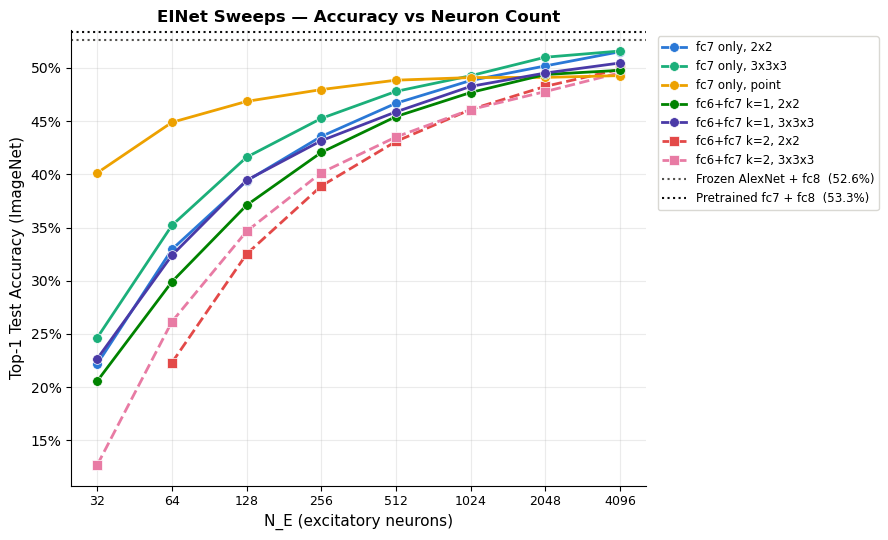

In [2]:
# ── Plot 1: Accuracy vs N_E ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5.5))

for s in SERIES:
    rows = sweep[s['label']]
    if not rows:
        continue
    nes, accs, _ = zip(*rows)
    marker = 'o' if s['ls'] == '-' else 's'
    ax.plot(nes, accs, marker=marker, color=s['color'], ls=s['ls'],
            lw=2, ms=7, label=s['label'], zorder=3 if s['ls']=='-' else 2,
            markeredgewidth=0.5, markeredgecolor='white')

ax.axhline(BASELINE*100, color='#52514e', ls=':', lw=1.5,
           label=f'Frozen AlexNet + fc8  ({BASELINE*100:.1f}%)')
if PRETRAINED_FC7:
    ax.axhline(PRETRAINED_FC7*100, color='#0b0b0b', ls=':', lw=1.5,
               label=f'Pretrained fc7 + fc8  ({PRETRAINED_FC7*100:.1f}%)')

ax.set_xscale('log', base=2)
ne_ticks = [32, 64, 128, 256, 512, 1024, 2048, 4096]
ax.set_xticks(ne_ticks); ax.set_xticklabels(ne_ticks, fontsize=9)
ax.set_xlabel('N_E (excitatory neurons)', fontsize=11)
ax.set_ylabel('Top-1 Test Accuracy (ImageNet)', fontsize=11)
ax.set_title('EINet Sweeps — Accuracy vs Neuron Count', fontsize=12, fontweight='bold')
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))
ax.grid(True, alpha=0.25, lw=0.8)
ax.spines[['top','right']].set_visible(False)
ax.legend(fontsize=8.5, framealpha=0.9, edgecolor='#d5d4cf',
          loc='upper left', bbox_to_anchor=(1.01, 1))

plt.tight_layout()
plt.savefig(FIG_DIR / 'acc_vs_ne.pdf', bbox_inches='tight')
plt.show()

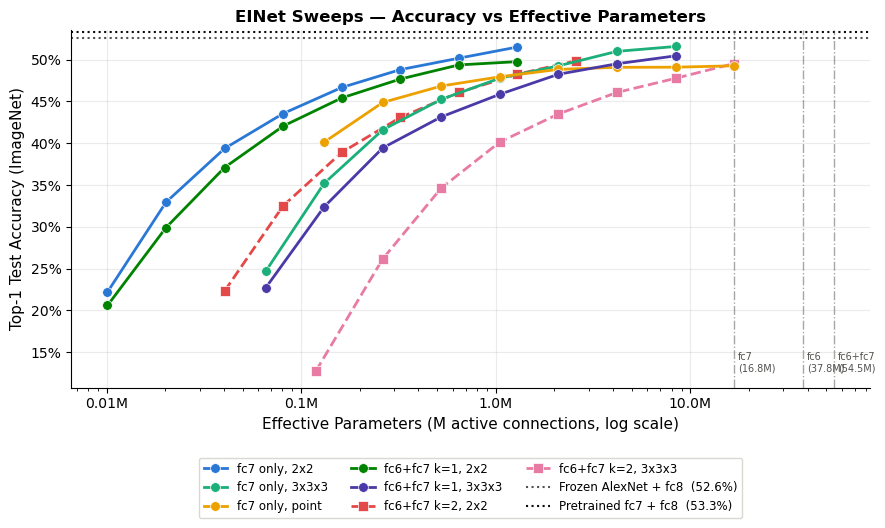

In [3]:
# ── Plot 2: Accuracy vs Effective Parameters ─────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5.5))

for s in SERIES:
    rows = sweep[s['label']]
    if not rows:
        continue
    nes, accs, effs = zip(*rows)
    effs_M = [e/1e6 for e in effs]
    marker = 'o' if s['ls'] == '-' else 's'
    ax.plot(effs_M, accs, marker=marker, color=s['color'], ls=s['ls'],
            lw=2, ms=7, label=s['label'], zorder=3 if s['ls']=='-' else 2,
            markeredgewidth=0.5, markeredgecolor='white')

ax.axhline(BASELINE*100, color='#52514e', ls=':', lw=1.5,
           label=f'Frozen AlexNet + fc8  ({BASELINE*100:.1f}%)')
if PRETRAINED_FC7:
    ax.axhline(PRETRAINED_FC7*100, color='#0b0b0b', ls=':', lw=1.5,
               label=f'Pretrained fc7 + fc8  ({PRETRAINED_FC7*100:.1f}%)')

for x, label in [
    ((4096*4096+4096)/1e6, 'fc7\n(16.8M)'),
    ((9216*4096+4096)/1e6, 'fc6\n(37.8M)'),
    ((9216*4096+4096+4096*4096+4096)/1e6, 'fc6+fc7\n(54.5M)'),
]:
    ax.axvline(x, color='#52514e', ls='-.', lw=1, alpha=0.5)
    ax.annotate(label, xy=(x, 0.04), xycoords=('data','axes fraction'),
                xytext=(3,0), textcoords='offset points',
                fontsize=7, color='#52514e', va='bottom')

ax.set_xscale('log')
ax.set_xlabel('Effective Parameters (M active connections, log scale)', fontsize=11)
ax.set_ylabel('Top-1 Test Accuracy (ImageNet)', fontsize=11)
ax.set_title('EINet Sweeps — Accuracy vs Effective Parameters', fontsize=12, fontweight='bold')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f'{x:.3g}M' if x < 1 else f'{x:.1f}M'))
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))
ax.grid(True, alpha=0.25, lw=0.8)
ax.spines[['top','right']].set_visible(False)
ax.legend(fontsize=8.5, framealpha=0.9, edgecolor='#d5d4cf',
          loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3)

plt.tight_layout()
plt.savefig(FIG_DIR / 'acc_vs_eff_params.pdf', bbox_inches='tight')
plt.show()